# Testing a Sequence of Risk Forecasts

This native Julia companion preserves the public NASDAQ observations, 2014 design cutoff, thresholds, tail models, bootstrap design and exception rules. The native fitting helper uses the original public simplex initialization and stopping tolerances; risk formulas and exception tests use RiskLabAI.jl. Fixed bootstrap positions reproduce seed 2202 without supplying fitted statistics. All calculations run in Julia. The resampling histogram retains the original bin convention and adds a panel whose bin bounds use the two drawdown measures. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## Forecasts Made Before the Held-Out Losses

For forecast date \(t\), define the exception indicator

$$
I_t=\mathbf{1}\{L_t>q_t\}.
$$

The loss observed on date \(t\) is \(L_t\), the quantile forecast made before that loss is \(q_t\), and \(\mathbf{1}\{\cdot\}\) equals one when its condition is true. At tail probability \(a\), a correctly calibrated quantile forecast has \(\Pr(I_t=1)=a\). This statement concerns quantile exceptions. It does not test the size of losses beyond the quantile or validate expected shortfall.

Row,Forecast,99% VaR (%),Varies through held-out period
,String,Float64,Bool
1,Gaussian,3.68696,false
2,Empirical,4.4378,false
3,Generalized Pareto,4.48156,false
4,Annual generalized Pareto,4.37402,true


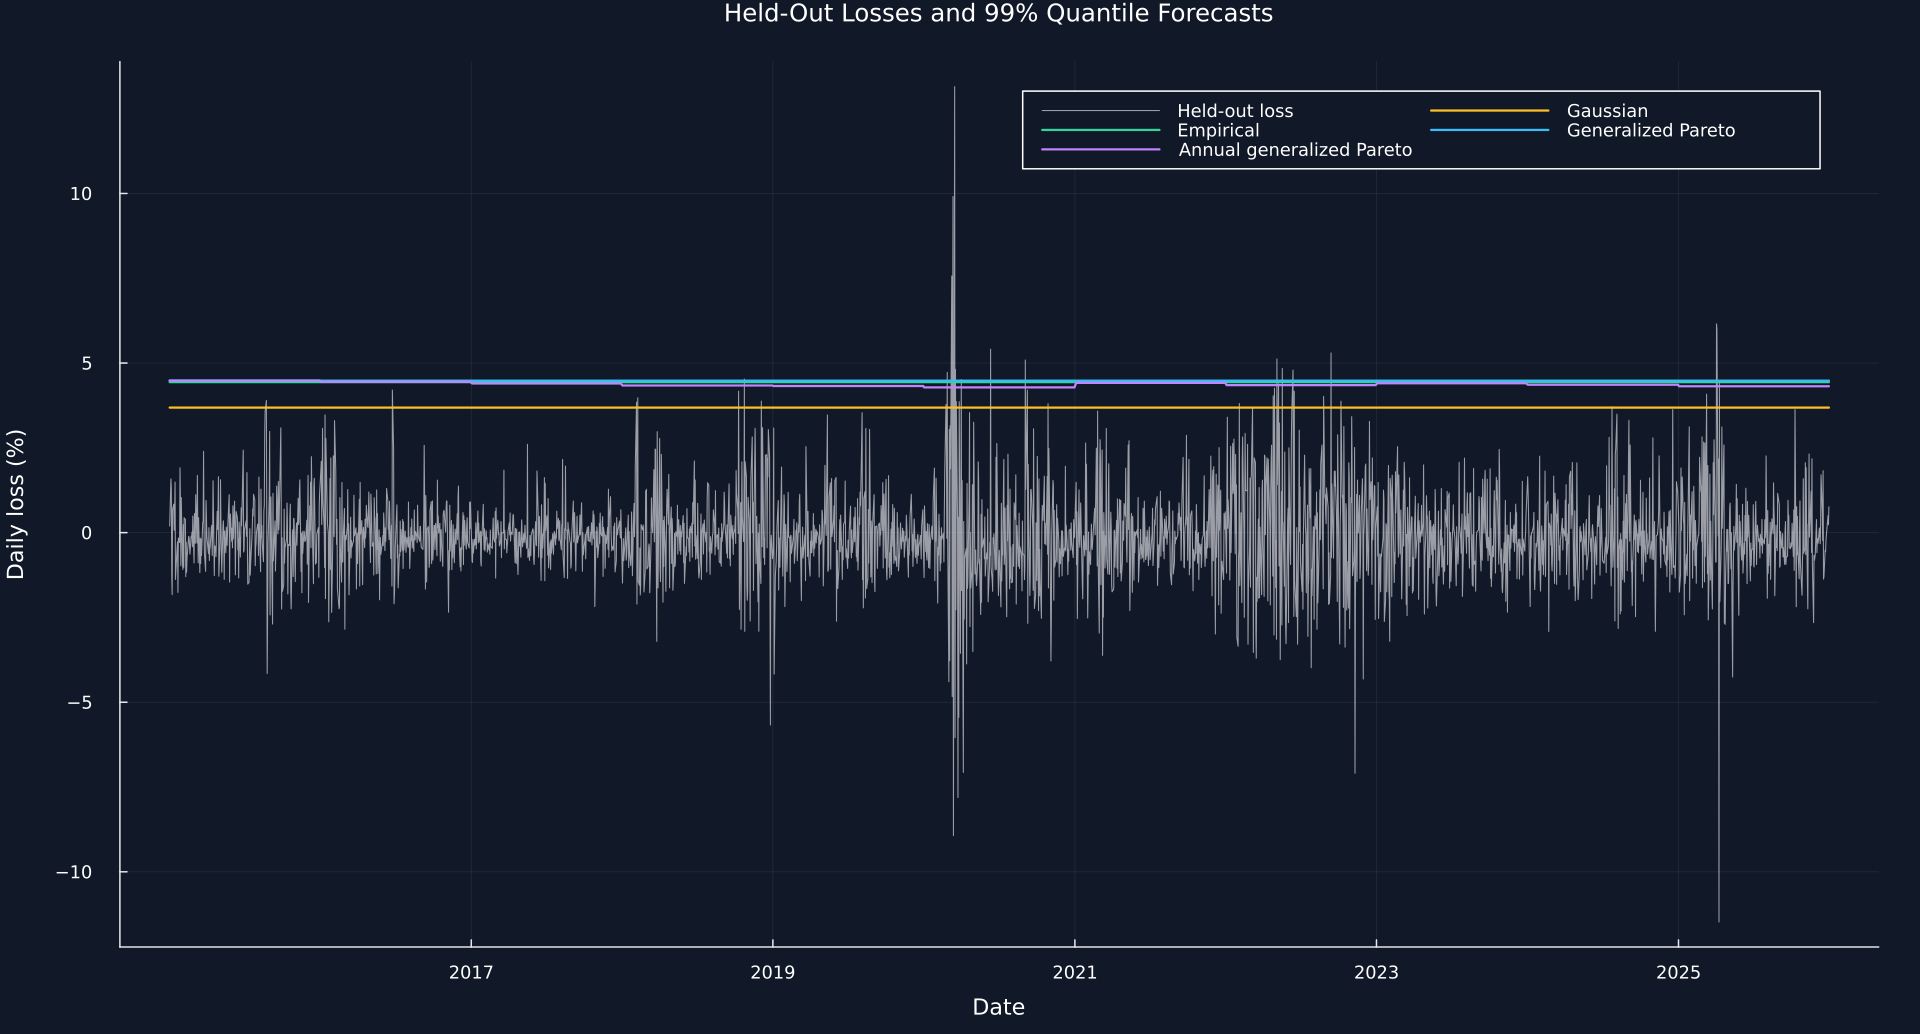

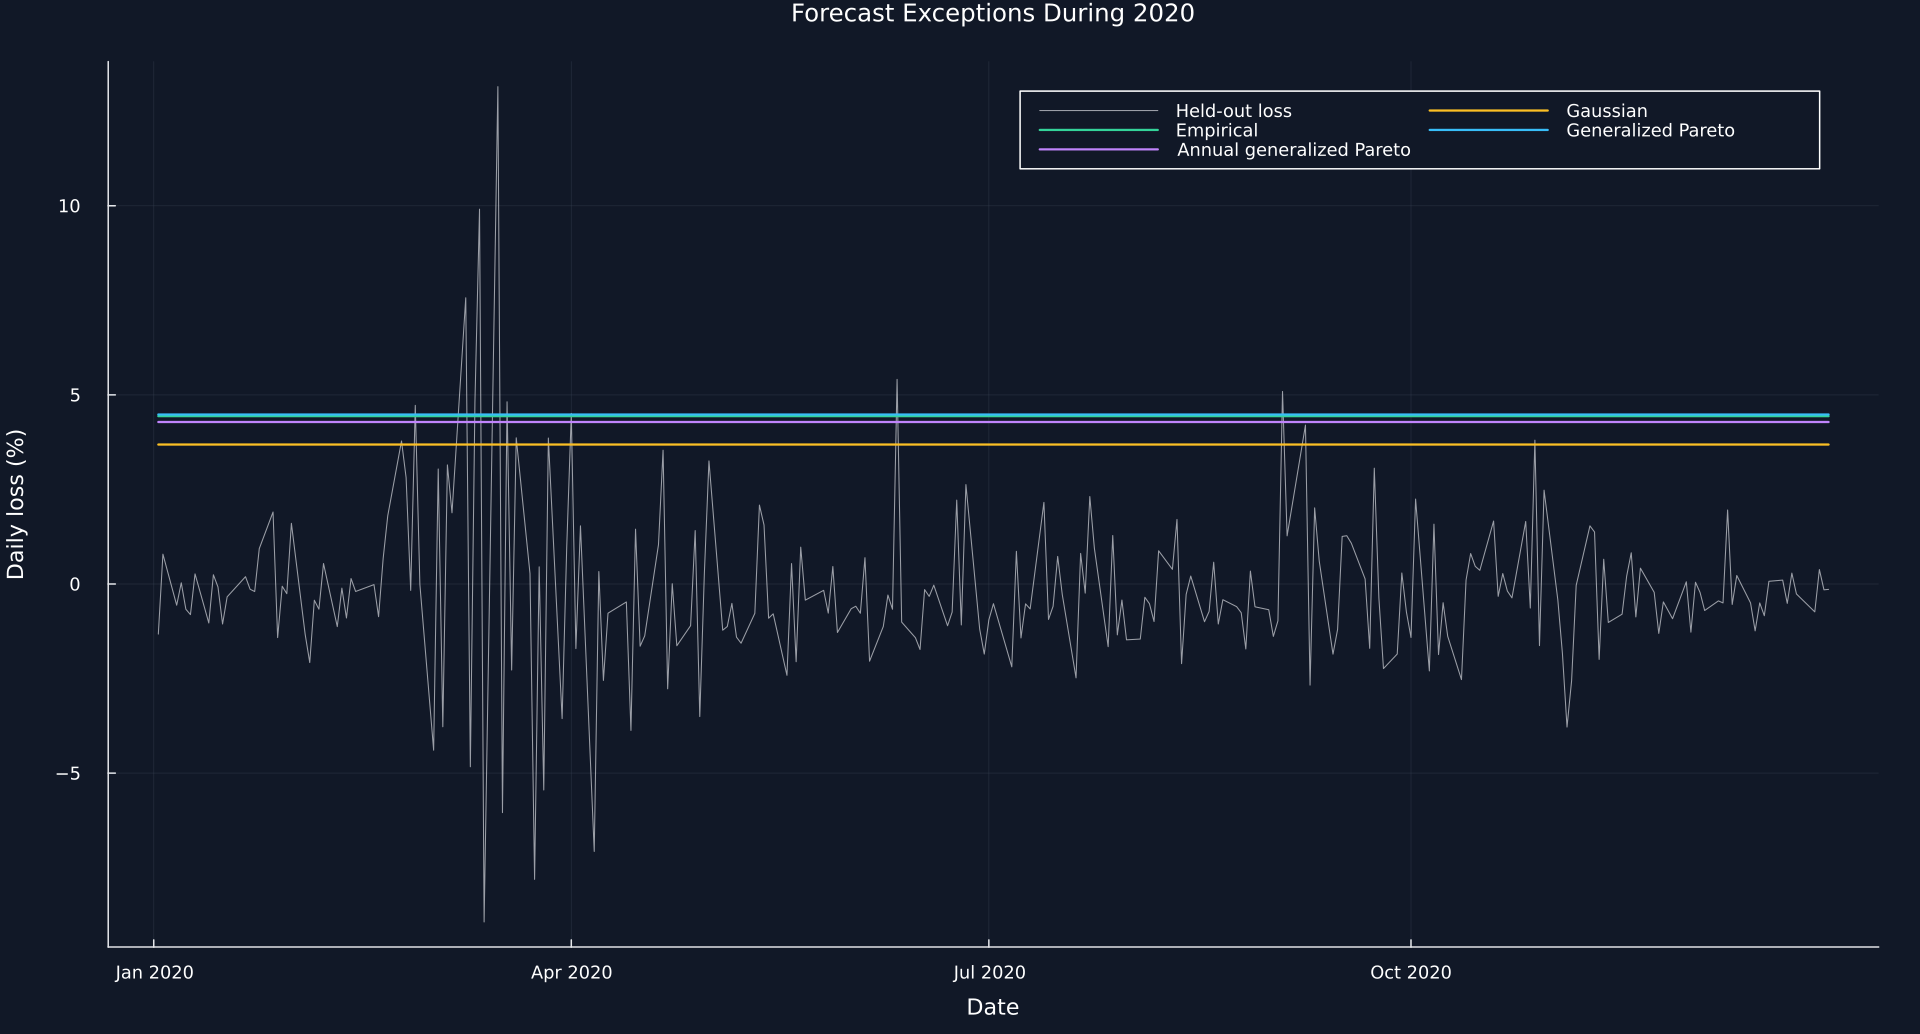

Row,Forecast,Information used,Update rule
,String,String,String
1,Gaussian,Design-sample loss mean and standard deviation,Frozen
2,Empirical,Design-sample loss quantile,Frozen
3,Generalized Pareto,Design-sample 95th-percentile excesses,Frozen
4,Annual generalized Pareto,All losses strictly before each forecast year,Once at each year start


In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("21_tail_risk");
using CSV, TOML, Printf
using Distributions: Normal,quantile,pdf
using RiskLabAI.Backtest: expected_shortfall,conditional_expected_drawdown,generalized_pareto_tail_risk,quantile_exception_tests
include(joinpath("..","support","BookTailFit.jl"))
using .BookTailFit
source_path = dataset_path("fred_nasdaq")
@assert isfile(source_path)
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:NASDAQCOM)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.NASDAQCOM)
log_returns = 100 .*log.(prices[2:end]./prices[1:end-1])
losses = -log_returns
simple_returns = expm1.(log_returns./100)
dates = price_dates[2:end]
design = findall(dates.<=Date(2014,12,31))
held = findall(dates.>=Date(2015,1,1))
design_losses,held_losses = losses[design],losses[held]
@assert length(design)==5287
@assert length(held)==2767
@assert last(dates[design])<first(dates[held])
@assert length(design)+length(held)==length(losses)
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
date_ticks(values;step=5) = let ticks=filter(date->first(values)<=date<=last(values),Date.(collect(year(first(values)):step:year(last(values))),1,1)); (Dates.value.(ticks),string.(year.(ticks))) end
save_data(DataFrame(date=dates,price=prices[2:end],log_return=log_returns,loss=losses,simple_return=simple_returns),paths,"backtest_observations")

function empirical_tail(values,probability)
    ordered = sort(values)
    count = (1-probability)*length(values)
    complete = floor(Int,count)
    total = complete>0 ? sum(ordered[end-complete+1:end]) : 0.
    fraction = count-complete
    fraction>0 && (total += fraction*ordered[end-complete])
    return total/count
end

function path_drawdown(values)
    wealth = cumprod(1 .+ values)
    return 1 .- wealth./accumulate(max,wealth)
end

function rolling_drawdowns(values,horizon)
    wealth = cumprod(1 .+ values)
    length(wealth)<horizon && return [maximum(path_drawdown(values))]
    return [maximum(1 .- current./accumulate(max,current)) for current in (view(wealth,start:start+horizon-1) for start in 1:length(wealth)-horizon+1)]
end

function annual_forecast(probability)
    forecast = zeros(length(held))
    records = NamedTuple[]
    for forecast_year in sort(unique(year.(dates[held])))
        history = findall(dates.<Date(forecast_year,1,1))
        threshold = quantile(losses[history],.95)
        fit = fit_public_pot(losses[history];threshold,probability)
        forecast[year.(dates[held]).==forecast_year] .= fit.value_at_risk
        push!(records,(year=forecast_year,through=last(dates[history]),observations=length(history),threshold=threshold,excesses=fit.exceedance_count,shape=fit.shape,scale=fit.scale,var=fit.value_at_risk,es=fit.expected_shortfall))
    end
    frame = DataFrame(records)
    rename!(frame,["Forecast year","History through","History observations","Threshold (%)","Excesses","Shape","Scale (%)","Forecast VaR (%)","Forecast ES (%)"])
    @assert all(year.(frame[!,"History through"]).<frame[!,"Forecast year"])
    @assert all(isfinite,forecast)
    return forecast,frame
end

function forecasts_at(probability)
    threshold = quantile(design_losses,.95)
    fit = fit_public_pot(design_losses;threshold,probability)
    annual,records = annual_forecast(probability)
    forecasts = [fill(mean(design_losses)+std(design_losses)*quantile(Normal(),probability),length(held)),fill(quantile(design_losses,probability),length(held)),fill(fit.value_at_risk,length(held)),annual]
    return forecasts,records
end

forecast_names = ["Gaussian","Empirical","Generalized Pareto","Annual generalized Pareto"]
forecast_colors = [palette.amber,palette.green,palette.cyan,violet]
forecasts,annual_records = forecasts_at(.99)
frozen = DataFrame("Forecast"=>forecast_names,"99% VaR (%)"=>[forecasts[1][1],forecasts[2][1],forecasts[3][1],mean(forecasts[4])],"Varies through held-out period"=>[false,false,false,true])
table(frozen,"frozen_forecasts","Forecast values fixed before or updated during the held-out period.")
forecast_frame = DataFrame("Date"=>dates[held],"Loss (%)"=>held_losses)
for (name,values) in zip(forecast_names,forecasts)
    forecast_frame[!,name*" forecast (%)"] = values
end
save_data(forecast_frame,paths,"heldout_loss_forecasts")
function forecast_plot(frame,title)
    figure = plot(Dates.value.(frame.Date),frame[!,"Loss (%)"];color=palette.text,alpha=.65,linewidth=.7,label="Held-out loss",xticks=date_ticks(frame.Date;step=year(last(frame.Date))==year(first(frame.Date)) ? 1 : 2),xlabel="Date",ylabel="Daily loss (%)",title,legend=:topright,legendcolumns=2,size=(1280,690))
    for (name,color) in zip(forecast_names,forecast_colors)
        plot!(figure,Dates.value.(frame.Date),frame[!,name*" forecast (%)"];color,label=name,linewidth=1.5)
    end
    if year(first(frame.Date))==year(last(frame.Date))
        ticks = [Date(year(first(frame.Date)),month,1) for month in [1,4,7,10]]
        plot!(figure;xticks=(Dates.value.(ticks),Dates.format.(ticks,"u yyyy")))
    end
    return figure
end
save_figure(forecast_plot(forecast_frame,"Held-Out Losses and 99% Quantile Forecasts"),paths,"heldout_loss_forecasts")
zoom = forecast_frame[year.(forecast_frame.Date).==2020,:]
save_data(zoom,paths,"heldout_forecast_zoom")
save_figure(forecast_plot(zoom,"Forecast Exceptions During 2020"),paths,"heldout_forecast_zoom")
@assert all(year.(annual_records[!,"History through"]).<annual_records[!,"Forecast year"])
@assert all(isfinite,Matrix(forecast_frame[:,2:end]))
forecast_definitions = DataFrame("Forecast"=>["Gaussian", "Empirical", "Generalized Pareto", "Annual generalized Pareto"],"Information used"=>["Design-sample loss mean and standard deviation", "Design-sample loss quantile", "Design-sample 95th-percentile excesses", "All losses strictly before each forecast year"],"Update rule"=>["Frozen", "Frozen", "Frozen", "Once at each year start"])
table(forecast_definitions,"forecast_definitions","Forecast definitions.")


## Testing exception frequency and clustering

If \(N=\sum_{t=1}^T I_t\) exceptions occur among \(T\) forecasts, the observed exception proportion is \(\widehat a=N/T\). The likelihood ratio for the declared probability \(a\) is

$$
\operatorname{LR}_{\mathrm{cov}}=2\left[N\log\!\left(\frac{\widehat a}{a}\right)+(T-N)\log\!\left(\frac{1-\widehat a}{1-a}\right)\right].
$$

The statistic compares the likelihood under the observed exception rate with the likelihood under the declared rate. It checks frequency, not clustering. Its usual reference distribution has one degree of freedom and is an approximation when exceptions are few.

Let \(n_{ij}\) count transitions from yesterday's exception state \(i\) to today's state \(j\), where \(i,j\in\{0,1\}\). The state-dependent exception rates are

$$
\widehat\pi_i=\frac{n_{i1}}{n_{i0}+n_{i1}},
$$

and the pooled transition rate is

$$
\widehat\pi=\frac{n_{01}+n_{11}}{T-1}.
$$

The independence likelihood ratio compares the two state-dependent rates with the pooled rate. The combined statistic is

$$
\operatorname{LR}_{\mathrm{cc}}=\operatorname{LR}_{\mathrm{cov}}+\operatorname{LR}_{\mathrm{ind}}.
$$

The combined test has two asymptotic degrees of freedom. If either previous-state row has no transitions, the implemented independence and combined statistics are left unidentified rather than assigned an invented value.

Row,Forecast,Held-out observations,Expected exceptions,Observed exceptions,Observed rate,Longest exception run
,String,Int64,Float64,Int64,Float64,Int64
1,Gaussian,2767,27.67,38,0.0137333,2
2,Empirical,2767,27.67,16,0.00578244,2
3,Generalized Pareto,2767,27.67,16,0.00578244,2
4,Annual generalized Pareto,2767,27.67,18,0.00650524,2


Row,Forecast,Coverage statistic,Coverage p-value,Independence statistic,Independence p-value,Combined statistic,Combined p-value
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Gaussian,3.48904,0.0617763,2.53558,0.111306,6.02462,0.0491779
2,Empirical,5.86132,0.0154772,8.95585,0.00276582,14.8172,0.000606026
3,Generalized Pareto,5.86132,0.0154772,8.95585,0.00276582,14.8172,0.000606026
4,Annual generalized Pareto,3.89492,0.0484323,7.997,0.00468549,11.8919,0.00261638


Row,Forecast,0 to 0,0 to 1,1 to 0,1 to 1
,String,Int64,Int64,Int64,Int64
1,Gaussian,2692,36,36,2
2,Empirical,2736,14,14,2
3,Generalized Pareto,2736,14,14,2
4,Annual generalized Pareto,2732,16,16,2


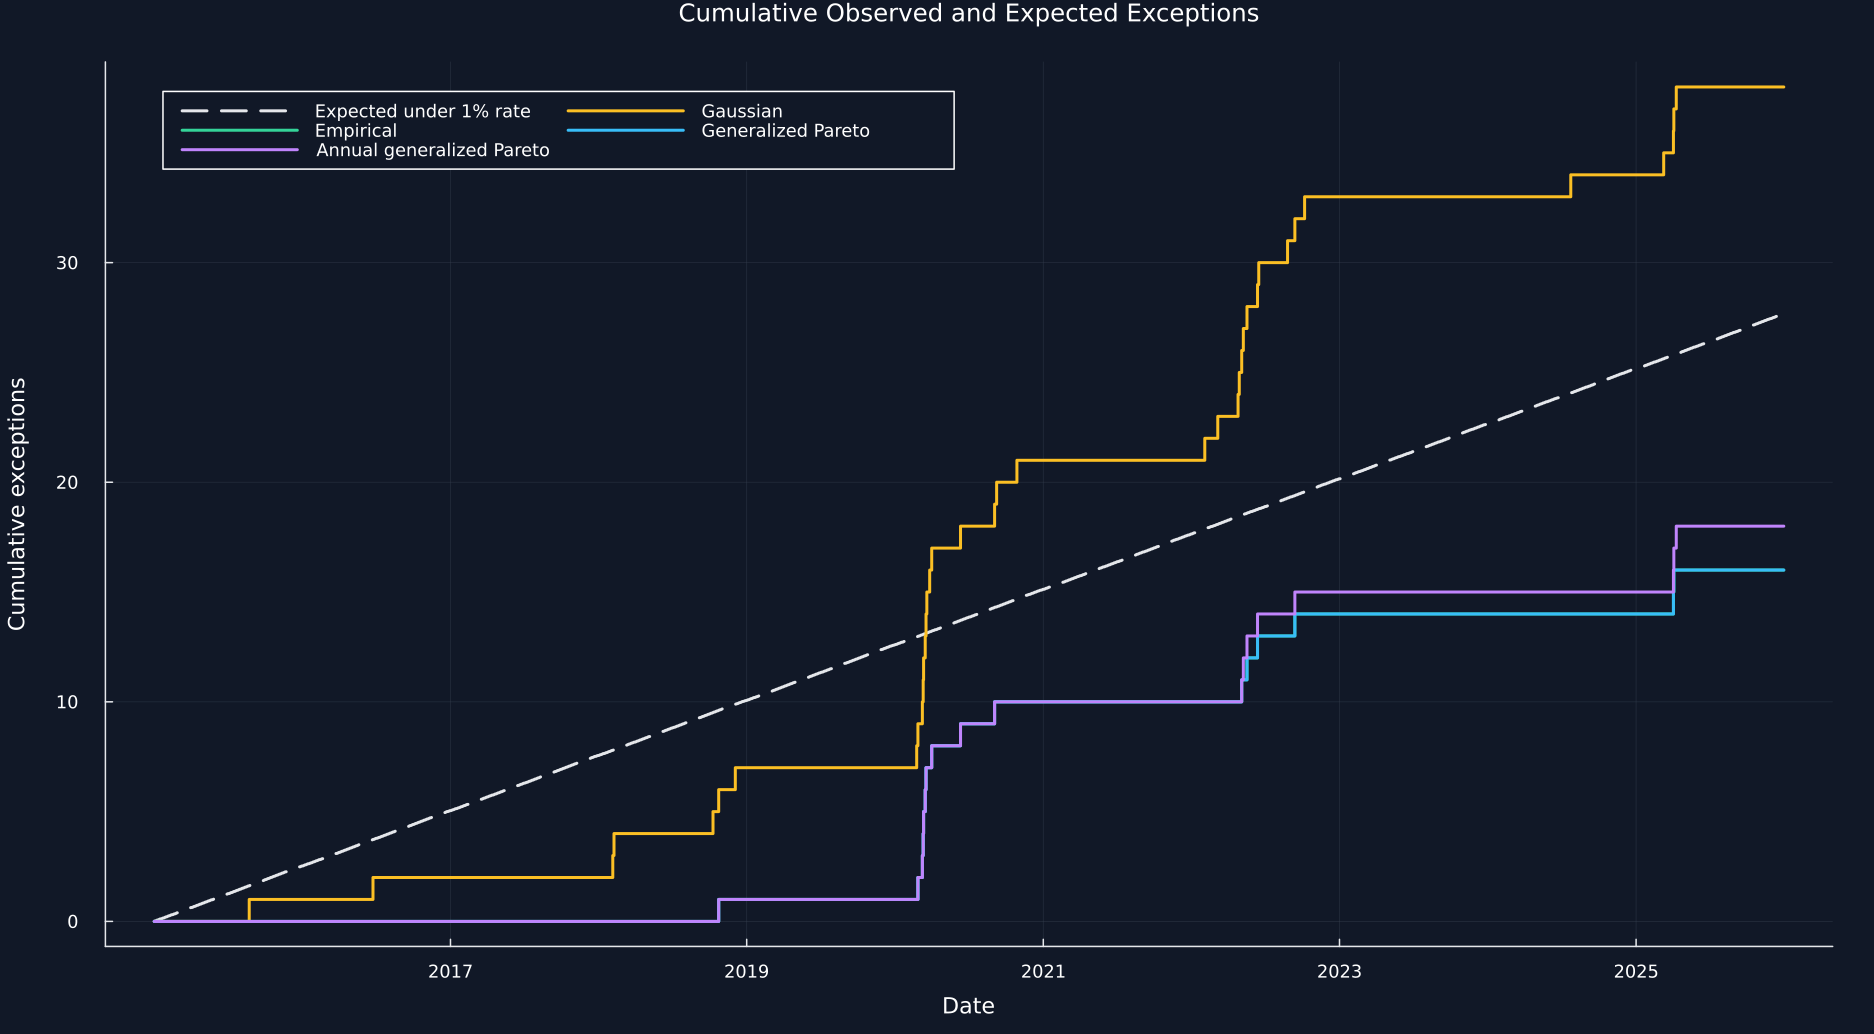

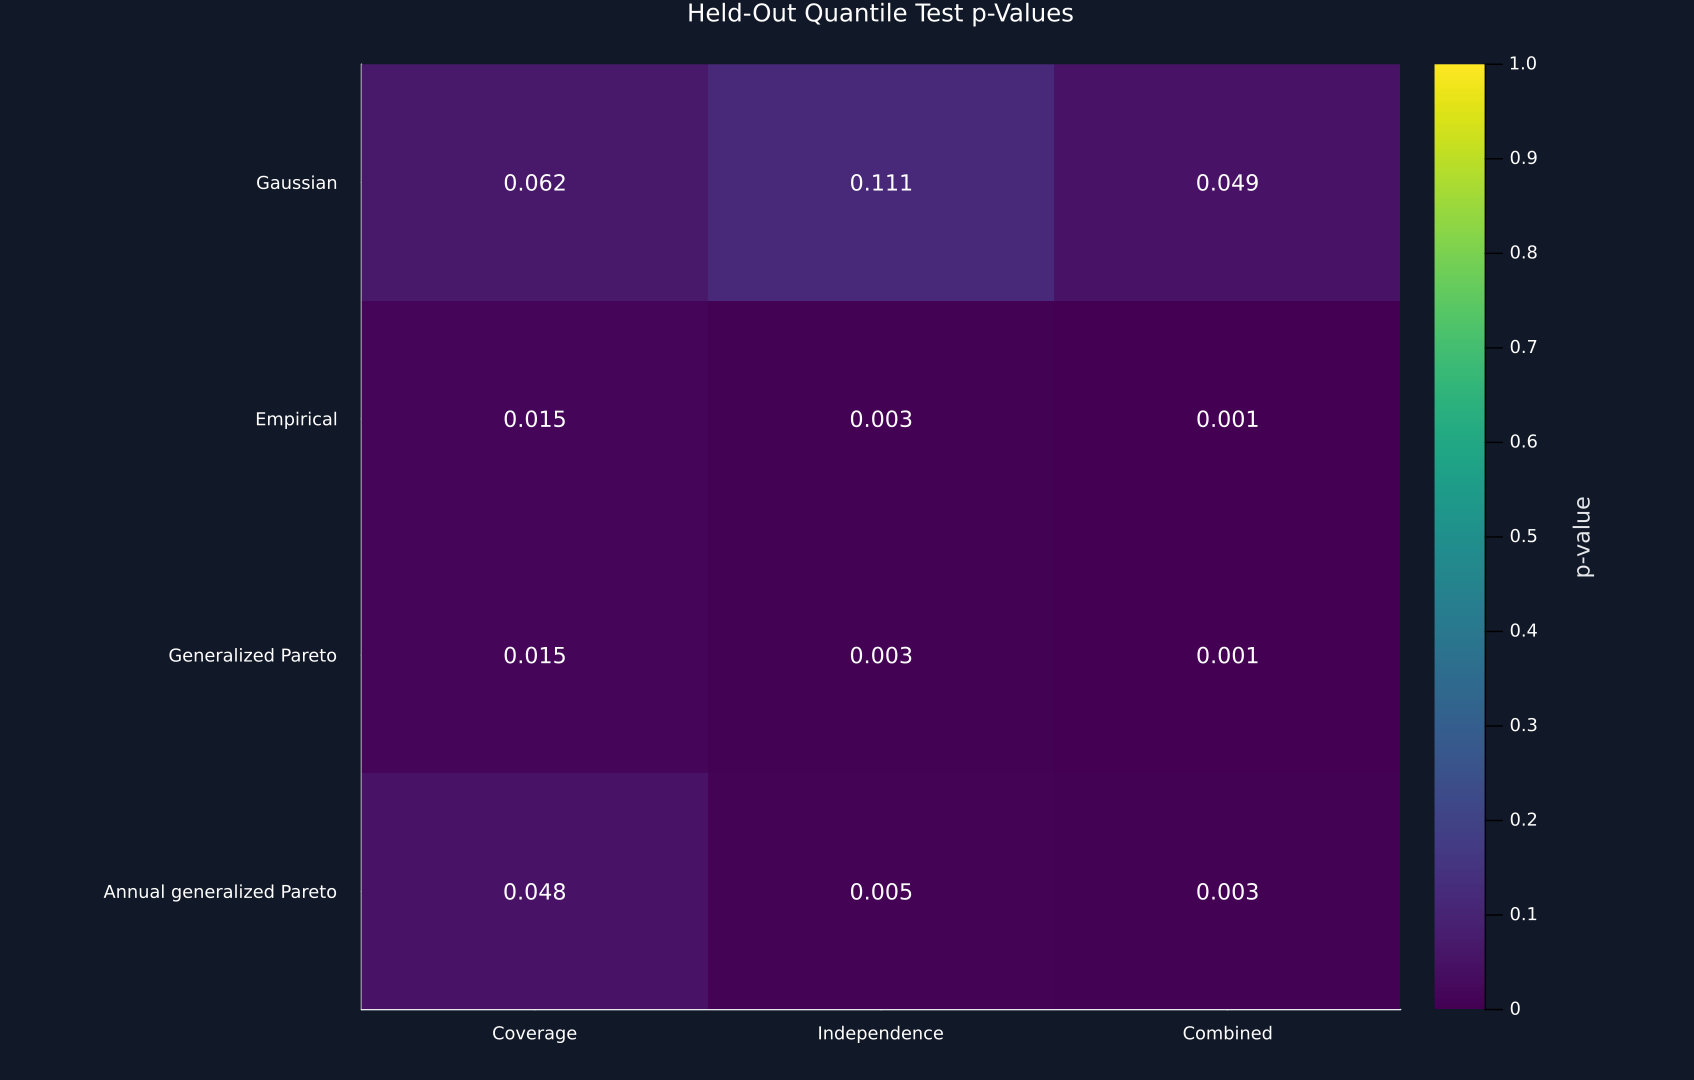

In [2]:
function longest_run(exceptions)
    largest,current = 0,0
    for value in exceptions
        current = value==1 ? current+1 : 0
        largest = max(largest,current)
    end
    return largest
end
summary_rows,test_rows,transition_rows = NamedTuple[],NamedTuple[],NamedTuple[]
cumulative = DataFrame("Date"=>dates[held],"Expected exceptions"=>collect(1:length(held)).*.01)
exception_rows = NamedTuple[]
for (name,forecast) in zip(forecast_names,forecasts)
    exceptions = Int.(held_losses.>forecast)
    result = quantile_exception_tests(exceptions;exception_probability=.01)
    push!(summary_rows,(name=name,observations=length(exceptions),expected=length(held)*.01,observed=result.exception_count,rate=mean(exceptions),longest=longest_run(exceptions)))
    push!(test_rows,(name=name,coverage=result.coverage_statistic,coverage_p=result.coverage_pvalue,independence=result.independence_statistic,independence_p=result.independence_pvalue,combined=result.conditional_coverage_statistic,combined_p=result.conditional_coverage_pvalue))
    push!(transition_rows,(name=name,n00=result.transitions[1,1],n01=result.transitions[1,2],n10=result.transitions[2,1],n11=result.transitions[2,2]))
    cumulative[!,name*" cumulative exceptions"] = cumsum(exceptions)
    append!(exception_rows,[(name=name,position=index,exception=exceptions[index]) for index in eachindex(exceptions)])
end
exception_summary,exception_tests,transition_counts = DataFrame(summary_rows),DataFrame(test_rows),DataFrame(transition_rows)
rename!(exception_summary,["Forecast","Held-out observations","Expected exceptions","Observed exceptions","Observed rate","Longest exception run"])
rename!(exception_tests,["Forecast","Coverage statistic","Coverage p-value","Independence statistic","Independence p-value","Combined statistic","Combined p-value"])
rename!(transition_counts,["Forecast","0 to 0","0 to 1","1 to 0","1 to 1"])
table(exception_summary,"exception_summary","Exception counts for the 99% held-out forecasts.")
table(exception_tests,"exception_tests","Coverage, independence, and combined tests at the 1% tail probability.")
table(transition_counts,"transition_counts","Transitions between exception states.")
save_data(DataFrame(exception_rows),paths,"heldout_exceptions")
save_data(cumulative,paths,"cumulative_exceptions")
figure = plot(Dates.value.(dates[held]),cumulative[!,"Expected exceptions"];color=palette.text,linestyle=:dash,label="Expected under 1% rate",xticks=date_ticks(dates[held];step=2),xlabel="Date",ylabel="Cumulative exceptions",title="Cumulative Observed and Expected Exceptions",legend=:topleft,legendcolumns=2,size=(1250,690))
for (name,color) in zip(forecast_names,forecast_colors)
    plot!(figure,Dates.value.(dates[held]),cumulative[!,name*" cumulative exceptions"];color,seriestype=:steppost,label=name)
end
save_figure(figure,paths,"cumulative_exceptions")
test_names = ["Coverage p-value","Independence p-value","Combined p-value"]
pvalues = DataFrame([(forecast=name,test=test,value=exception_tests[index,test]) for test in test_names for (index,name) in enumerate(forecast_names)])
rename!(pvalues,["Forecast","Test","p-value"])
save_data(pvalues,paths,"backtest_pvalue_heatmap")
matrix = Matrix(exception_tests[:,test_names])
figure = heatmap(1:3,1:4,matrix;xticks=(1:3,["Coverage","Independence","Combined"]),yticks=(1:4,forecast_names),yflip=true,clims=(0,1),color=:viridis,colorbar_title="p-value",title="Held-Out Quantile Test p-Values",grid=false,left_margin=16Plots.mm,right_margin=15Plots.mm,size=(1130,720))
for row in 1:4,column in 1:3
    annotate!(figure,column,row,text(@sprintf("%.3f",matrix[row,column]),10,matrix[row,column]<.55 ? "#FFFFFF" : "#111827"))
end
save_figure(figure,paths,"backtest_pvalue_heatmap")
@assert exception_summary[3,"Observed exceptions"]==16
@assert exception_tests[3,"Coverage p-value"]<.05
@assert exception_tests[3,"Independence p-value"]<.05
@assert exception_tests[3,"Combined p-value"]<.05


## Testing annual updates without future data

For forecast year \(y\), the updated threshold is

$$
u_y=Q_{0.95}\bigl(\{L_t:t<\text{January 1 of year }y\}\bigr).
$$

The function \(Q_{0.95}\) is the empirical 95th percentile and the set contains only losses observed before year \(y\). A generalized Pareto fit using these past losses produces one forecast for that calendar year. Updating preserves the time order, but it does not guarantee correct exception frequency or independence.

At tail probability \(a\), the expected exception count over \(T\) forecasts is

$$
\mathbb{E}[N]=Ta.
$$

The count \(N\) is random even under a correct forecast. Comparing observed and expected counts at several declared levels is a sensitivity check. It does not justify selecting a level after observing which test passes.

Row,Forecast year,History through,History observations,Threshold (%),Excesses,Shape,Scale (%),Forecast VaR (%),Forecast ES (%)
,Int64,Date,Int64,Float64,Int64,Float64,Float64,Float64,Float64
1,2015,2014-12-31,5287,2.61434,265,0.135989,1.03608,4.48156,5.9746
2,2016,2015-12-31,5539,2.57528,277,0.119066,1.05429,4.44581,5.89543
3,2017,2016-12-30,5791,2.55081,290,0.121619,1.03732,4.39687,5.83341
4,2018,2017-12-29,6042,2.51057,303,0.127522,1.02085,4.33804,5.7752
5,2019,2018-12-31,6293,2.50937,315,0.117604,1.02333,4.32391,5.72546
6,2020,2019-12-31,6546,2.4877,328,0.117565,1.01157,4.28259,5.66806
7,2021,2020-12-31,6799,2.51071,340,0.135411,1.05929,4.4158,5.93938
8,2022,2021-12-31,7051,2.50542,353,0.157706,1.00556,4.34938,5.88846
9,2023,2022-12-30,7302,2.5441,366,0.131942,1.03515,4.40336,5.87845


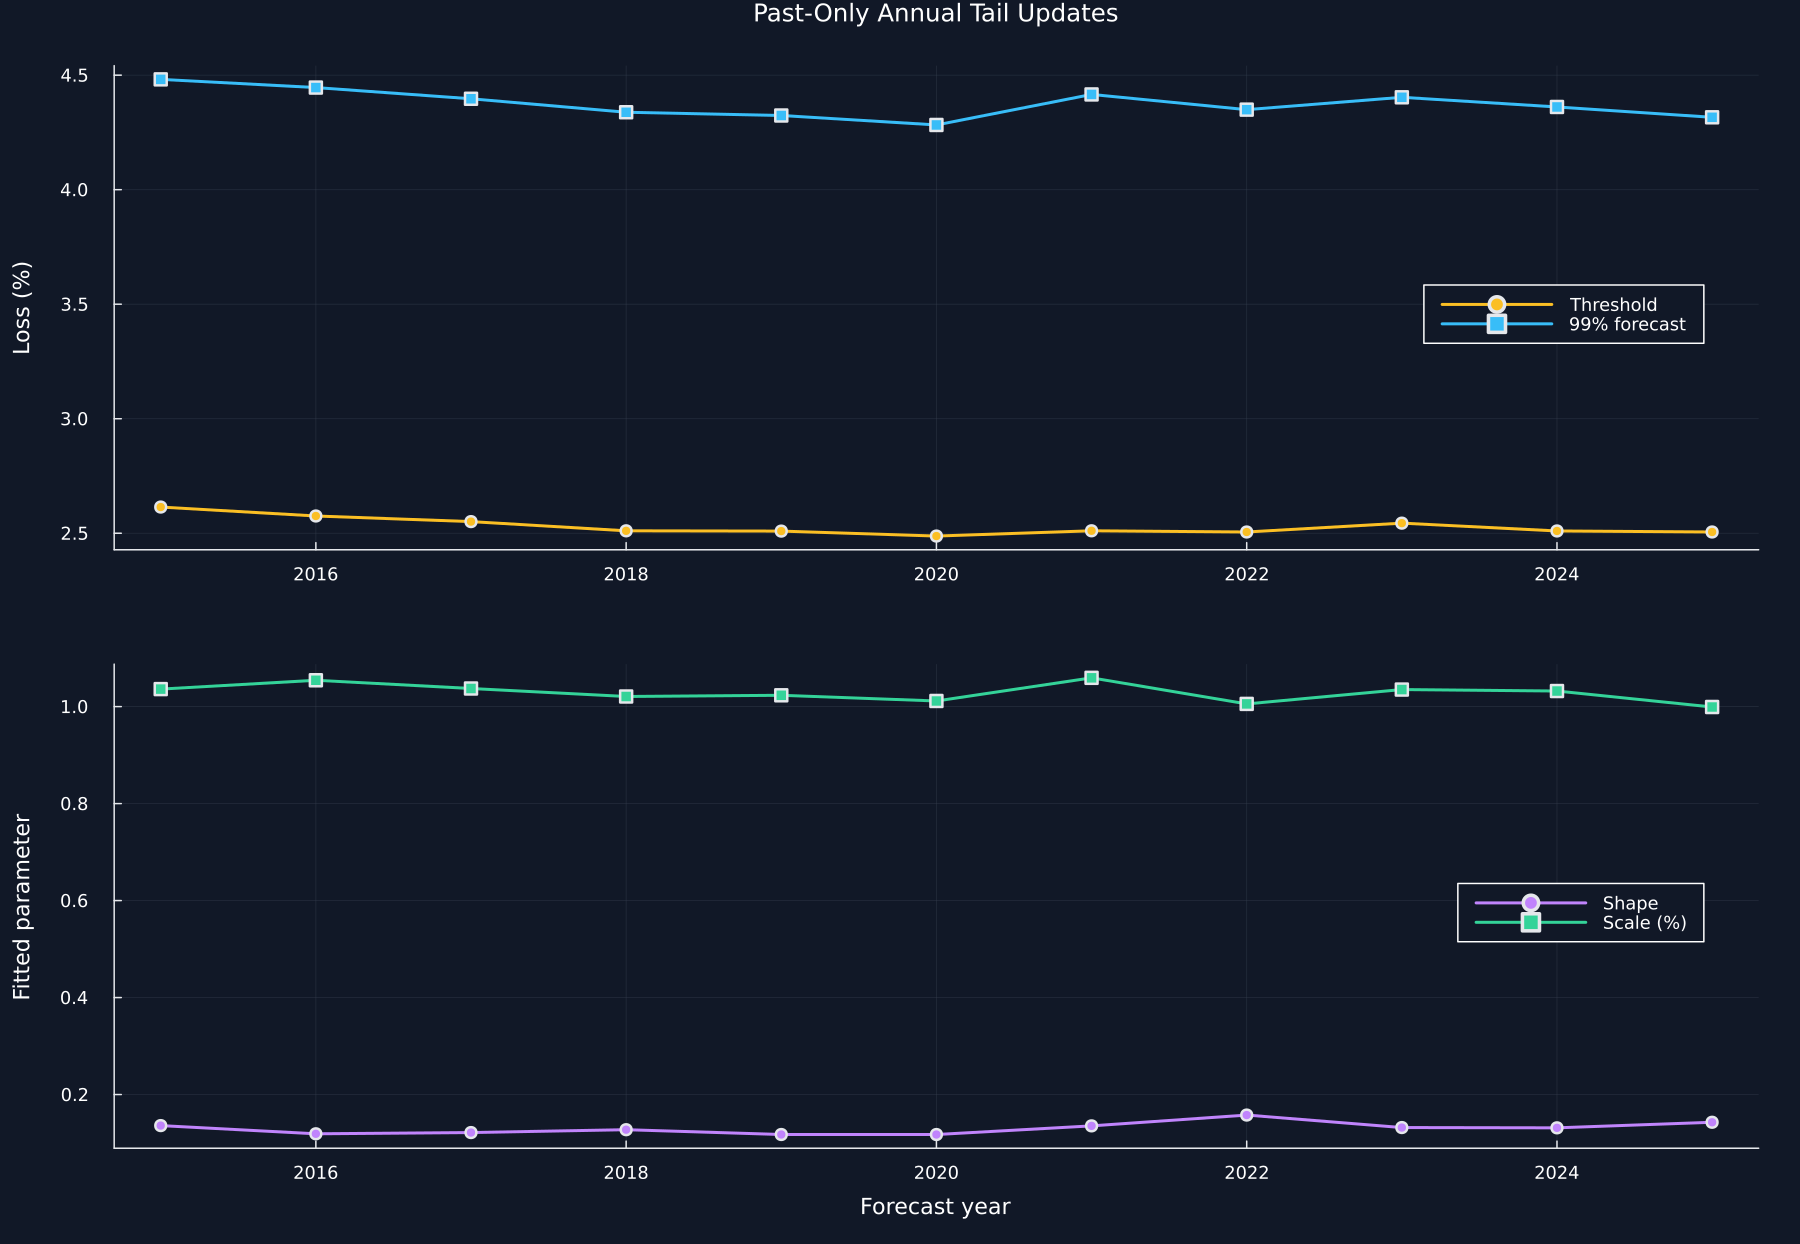

Row,Probability level,Forecast,Expected exceptions,Observed exceptions,Coverage p-value,Independence p-value,Combined p-value
,Float64,String,Float64,Int64,Float64,Float64,Float64
1,0.975,Gaussian,69.175,59,0.203891,0.0445553,0.0593183
2,0.975,Empirical,69.175,51,0.0203554,0.0155905,0.00364347
3,0.975,Generalized Pareto,69.175,50,0.0141101,0.0134458,0.00231834
4,0.975,Annual generalized Pareto,69.175,53,0.0400932,0.0207126,0.00837608
5,0.99,Gaussian,27.67,38,0.0617763,0.111306,0.0491779
6,0.99,Empirical,27.67,16,0.0154772,0.00276582,0.000606026
7,0.99,Generalized Pareto,27.67,16,0.0154772,0.00276582,0.000606026
8,0.99,Annual generalized Pareto,27.67,18,0.0484323,0.00468549,0.00261638
9,0.995,Gaussian,13.835,23,0.0241754,0.0137673,0.00379197


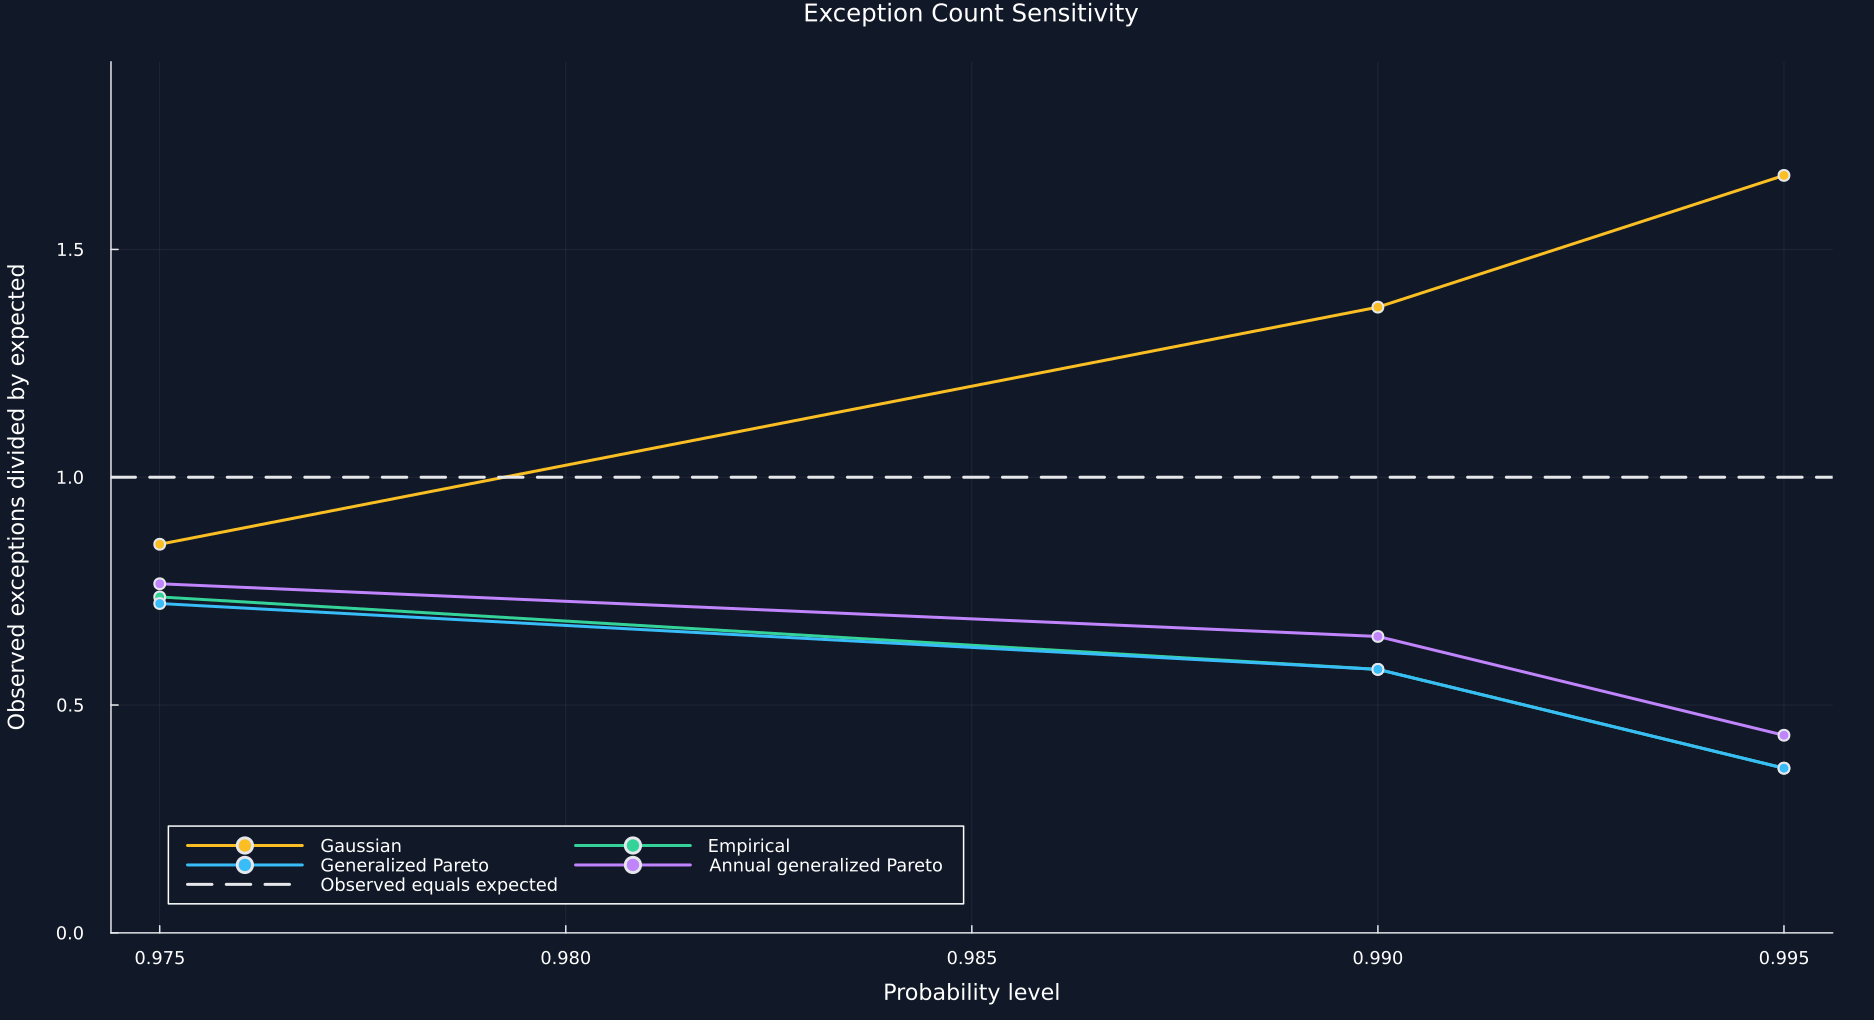

Row,Input,Coverage identified,Independence identified
,String,Bool,Bool
1,Alternating zero and one,true,true
2,No exceptions,true,false


Row,Result,Permitted reading,Excluded reading
,String,String,String
1,Small p-value for coverage,Observed exception frequency conflicts with the declared rate,Expected shortfall is invalid
2,Small p-value for independence,Exceptions show first-order clustering,A unique economic cause is proven
3,Large p-value,The test does not reject in this sample,The forecast model is true
4,Updated forecast,Only past observations enter each update,Updating guarantees calibration


In [3]:
annual_main,annual_records = annual_forecast(.99)
table(annual_records,"annual_pot_updates","Past-only annual generalized Pareto updates.")
annual_plot = select(annual_records,["Forecast year","Threshold (%)","Shape","Scale (%)","Forecast VaR (%)"])
save_data(annual_plot,paths,"annual_pot_updates")
years = annual_plot[!,"Forecast year"]
p1 = plot(years,annual_plot[!,"Threshold (%)"];color=palette.amber,marker=:circle,label="Threshold",title="Past-Only Annual Tail Updates",ylabel="Loss (%)",legend=:right)
plot!(p1,years,annual_plot[!,"Forecast VaR (%)"];color=palette.cyan,marker=:square,label="99% forecast")
p2 = plot(years,annual_plot.Shape;color=violet,marker=:circle,label="Shape",xlabel="Forecast year",ylabel="Fitted parameter",legend=:right)
plot!(p2,years,annual_plot[!,"Scale (%)"];color=palette.green,marker=:square,label="Scale (%)")
save_figure(plot(p1,p2;layout=(2,1),size=(1200,830)),paths,"annual_pot_updates")
sensitivity_rows,coverage_rows,forecast_records = NamedTuple[],NamedTuple[],NamedTuple[]
for probability in [.975,.99,.995]
    forecasts,records = forecasts_at(probability)
    save_data(records,paths,"annual_records_"*string(round(Int,1000*probability)))
    for (name,forecast) in zip(forecast_names,forecasts)
        exceptions = Int.(held_losses.>forecast)
        result = quantile_exception_tests(exceptions;exception_probability=1-probability)
        expected = length(held)*(1-probability)
        push!(sensitivity_rows,(probability=probability,name=name,expected=expected,observed=result.exception_count,coverage=result.coverage_pvalue,independence=result.independence_pvalue,combined=result.conditional_coverage_pvalue))
        push!(coverage_rows,(probability=probability,name=name,ratio=result.exception_count/expected))
        append!(forecast_records,[(probability=probability,name=name,position=index,forecast=forecast[index],exception=exceptions[index]) for index in eachindex(forecast)])
    end
end
sensitivity,coverage = DataFrame(sensitivity_rows),DataFrame(coverage_rows)
rename!(sensitivity,["Probability level","Forecast","Expected exceptions","Observed exceptions","Coverage p-value","Independence p-value","Combined p-value"])
rename!(coverage,["Probability level","Forecast","Observed divided by expected"])
table(sensitivity,"sensitivity_backtests","Held-out exception tests across three probability levels.")
save_data(coverage,paths,"coverage_sensitivity")
save_data(DataFrame(forecast_records),paths,"sensitivity_forecasts")
figure = plot(;xlabel="Probability level",ylabel="Observed exceptions divided by expected",title="Exception Count Sensitivity",legend=:bottomleft,legendcolumns=2,size=(1250,680),ylims=(0,1.15*max(1.,maximum(coverage[!,"Observed divided by expected"]))))
for (name,color) in zip(forecast_names,forecast_colors)
    rows = coverage.Forecast.==name
    plot!(figure,coverage[rows,"Probability level"],coverage[rows,"Observed divided by expected"];color,marker=:circle,label=name)
end
hline!(figure,[1.];color=palette.text,linestyle=:dash,label="Observed equals expected")
save_figure(figure,paths,"coverage_sensitivity")
alternating = quantile_exception_tests(repeat([0,1],20);exception_probability=.5)
no_exceptions = quantile_exception_tests(zeros(Int,40);exception_probability=.01)
edge_checks = DataFrame("Input"=>["Alternating zero and one","No exceptions"],"Coverage identified"=>[!isnothing(alternating.coverage_statistic),!isnothing(no_exceptions.coverage_statistic)],"Independence identified"=>[!isnothing(alternating.independence_statistic),!isnothing(no_exceptions.independence_statistic)])
table(edge_checks,"library_edge_case_checks","Identification behavior for two exception sequences.")
@assert all(year.(annual_records[!,"History through"]).<annual_records[!,"Forecast year"])
@assert nrow(sensitivity)==12
@assert isnothing(no_exceptions.independence_statistic)
limits = DataFrame("Result"=>["Small p-value for coverage", "Small p-value for independence", "Large p-value", "Updated forecast"],"Permitted reading"=>["Observed exception frequency conflicts with the declared rate", "Exceptions show first-order clustering", "The test does not reject in this sample", "Only past observations enter each update"],"Excluded reading"=>["Expected shortfall is invalid", "A unique economic cause is proven", "The forecast model is true", "Updating guarantees calibration"])
table(limits,"backtest_interpretation_limits","Backtest interpretation limits.")
